# ① 데이터 불러오기와 구조 확인
### pd.read_csv(), head(), info(), isnull().sum()

In [1]:
import pandas as pd

PATH = "data/"

In [2]:
clinical = pd.read_csv(PATH + "clinical.csv", encoding = 'utf-8-sig')
clinical.head()

,patient_id,age,sex,cancer_type,stage
0,P001,62.0,F,BRCA,II
1,P002,55.0,M,BRCA,III
2,P003,NaN,F,BRCA,I
3,P004,48.0,NaN,BRCA,II
4,P005,66.0,F,BRCA,NaN


In [3]:
clinical.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   patient_id   12 non-null     str    
 1   age          11 non-null     float64
 2   sex          11 non-null     str    
 3   cancer_type  12 non-null     str    
 4   stage        11 non-null     str    
dtypes: float64(1), str(4)
memory usage: 746.0 bytes


In [4]:
mutation = pd.read_csv(PATH + 'mutation.csv', encoding="utf-8-sig")
mutation.head()

,patient_id,gene,variant,consequence
0,P001,TP53,R175H,Missense
1,P001,PIK3CA,H1047R,Missense
2,P001,GATA3,Q34*,Nonsense
3,P002,TP53,R273H,NaN
4,P002,ERBB2,S310F,Missense


In [5]:
mutation.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   patient_id   23 non-null     str  
 1   gene         23 non-null     str  
 2   variant      23 non-null     str  
 3   consequence  22 non-null     str  
dtypes: str(4)
memory usage: 1.3 KB


In [6]:
clinical.isnull().sum()

patient_id     0
age            1
sex            1
cancer_type    0
stage          1
dtype: int64

In [7]:
clinical.isnull().sum()

patient_id     0
age            1
sex            1
cancer_type    0
stage          1
dtype: int64

In [8]:
mutation.isnull().sum()

patient_id     0
gene           0
variant        0
consequence    1
dtype: int64

# ② 결측치 처리
### fillna(), dropna()

In [9]:
clinical['age'] = clinical['age'].fillna(clinical['age'].median()) #age결측치를 중앙값으로 채움
clinical.isnull().sum()

patient_id     0
age            0
sex            1
cancer_type    0
stage          1
dtype: int64

In [10]:
# 원본 변이 데이터 보존
mutation_raw = pd.read_csv(
    PATH + "mutation.csv",
    encoding="utf-8-sig"
)

# ③ 중복 데이터 탐지 및 처리
### duplicated(), drop_duplicates()

In [11]:
print("mutation 중복 건수:", mutation.duplicated(subset=['patient_id', 'gene', 'variant']).sum())
print("clinical 중복 건수:", clinical.duplicated(subset=['patient_id']).sum())

mutation 중복 건수: 1
clinical 중복 건수: 0


In [12]:
dup_mut = mutation[mutation.duplicated(subset=['patient_id', 'gene', 'variant'], keep=False)]
print(dup_mut)
# keep 파라미터의 3가지 선택지 (False, 'first', 'last')
# keep=False:중복에 참여한 모든 행을 다 보여줌
# keep='first': 첫 번째 행을 제외한 나머지 중복 행들만 보여줌
# keep='last': 마지막 행을 제외한 나머지 중복 행들만 보여줌

   patient_id  gene variant consequence
19       P010  TP53   R248W    Missense
21       P010  TP53   R248W    Missense


In [13]:
dup_mut_sorted = mutation[mutation.duplicated(subset=['patient_id', 'gene', 'variant'], keep=False)].sort_values(by='patient_id')
#현재 데이터에서는 이미 정렬되어있지만 방대한 양의 실무 데이터를 다룰땐 정렬 해주기
print(dup_mut_sorted)

   patient_id  gene variant consequence
19       P010  TP53   R248W    Missense
21       P010  TP53   R248W    Missense


In [14]:
# consequence 분석용 데이터: 중복 제거 후 consequence 결측치 제외
mutation_consequence = mutation.dropna(
    subset=["consequence"]
).copy()

mutation_consequence.info()

<class 'pandas.DataFrame'>
Index: 22 entries, 0 to 22
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   patient_id   22 non-null     str  
 1   gene         22 non-null     str  
 2   variant      22 non-null     str  
 3   consequence  22 non-null     str  
dtypes: str(4)
memory usage: 1.3 KB


In [15]:
print("mutation 남은 중복 건수:", mutation.duplicated(subset=['patient_id', 'gene', 'variant']).sum())

mutation 남은 중복 건수: 1


# ④ 데이터 간 환자 ID 비교와 병합
### set(), 차집합(-), pd.merge()

In [16]:
clinical_patients = set(clinical['patient_id'])
mutation_patients = set(mutation['patient_id'])

print("1) mutation에는 있지만 clinical에는 없는 환자:", mutation_patients - clinical_patients)
print("2) clinical에는 있지만 mutation에는 없는 환자:", clinical_patients - mutation_patients)

# set(집합) 주요 연산 요약:
# - 합집합 (|): 양쪽 집합의 모든 요소를 중복 없이 합침 (A | B)
# - 교집합 (&): 양쪽 집합에 공통으로 존재하는 요소만 추출 (A & B)
# - 차집합 (-): 앞쪽 집합에서 뒤쪽 집합의 요소를 제외하고 남은 것 추출 (A - B)

1) mutation에는 있지만 clinical에는 없는 환자: {'P013'}
2) clinical에는 있지만 mutation에는 없는 환자: {'P012', 'P011'}


In [17]:
# 환자 ID('patient_id')를 기준으로 clinical과 mutation 데이터를 Left Join 병합
# 환자의 임상적 특성(나이, 병기 등)에 따라 변이 건수가 어떻게 달라지는지를 분석하는 것이 목적이었기에
# 임상 데이터를 기준으로 모든 환자의 임상 정보를 유지하고, 환자 ID를 기준으로 변이 정보를 결합는 Left Join을 사용
df_merged = pd.merge(clinical, mutation, on='patient_id', how='left')
print("병합 후 전체 데이터 크기:", df_merged.shape)
print(df_merged.head())
print(df_merged.iloc[20:22, :]) 
#임상 데이터에는 있지만 변이 데이터에는 없는 P011, P012 환자가 병합 후에도 유지되는지 확인
#변이 기록이 없다고 해서 변이가 없다고 해석하면 안됨(검사를 하지 않았거나 데이터 누락 가능성 등)

병합 후 전체 데이터 크기: (24, 8)
  patient_id   age sex cancer_type stage    gene variant consequence
0       P001  62.0   F        BRCA    II    TP53   R175H    Missense
1       P001  62.0   F        BRCA    II  PIK3CA  H1047R    Missense
2       P001  62.0   F        BRCA    II   GATA3    Q34*    Nonsense
3       P002  55.0   M        BRCA   III    TP53   R273H         NaN
4       P002  55.0   M        BRCA   III   ERBB2   S310F    Missense
   patient_id   age sex cancer_type stage   gene variant consequence
20       P010  74.0   F        BRCA    IV  BRCA2  Q1037*    Nonsense
21       P010  74.0   F        BRCA    IV   TP53   R248W    Missense


# ⑤ 유전자·환자·병기별 집계와 시각화
### value_counts(), groupby(), agg(), Plotly (px.bar(), px.pie())

In [18]:
mutation_count = df_merged.groupby('patient_id')['gene'].count().reset_index()
mutation_count

,patient_id,gene
0,P001,3
1,P002,2
2,P003,1
3,P004,3
4,P005,4
5,P006,1
6,P007,2
7,P008,2
8,P009,1
9,P010,3


In [19]:
top_genes = df_merged['gene'].value_counts().reset_index()
top_genes.columns = ['gene', 'mutation_count']

print("=== 주요 변이 유전자 상위 목록 ===")
print(top_genes)

=== 주요 변이 유전자 상위 목록 ===
     gene  mutation_count
0    TP53               8
1  PIK3CA               4
2   GATA3               2
3   ERBB2               2
4   BRCA1               2
5   BRCA2               2
6    CDH1               1
7    PTEN               1


#### <주요 유전자별 변이 발생 빈도>

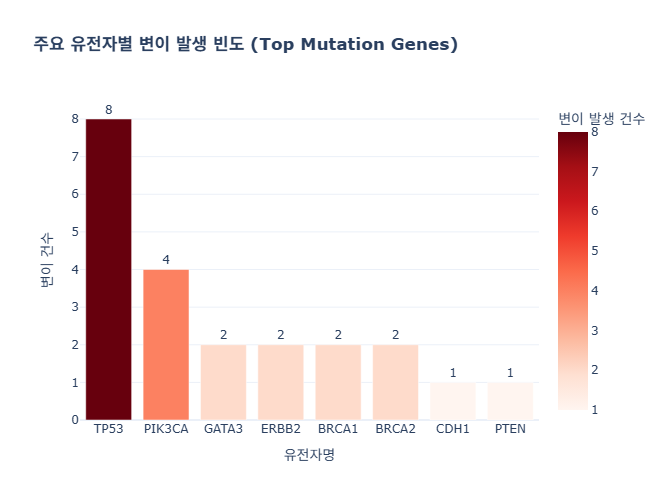

In [20]:
import plotly.express as px

gene_counts = df_merged['gene'].value_counts().reset_index()
gene_counts.columns = ['gene', 'count']

# 주요 유전자 변이 빈도 바 차트 생성
fig_bar = px.bar(
    gene_counts,
    x='gene',
    y='count',
    text='count',
    title='<b>주요 유전자별 변이 발생 빈도 (Top Mutation Genes)</b>',
    labels={'gene': '유전자 (Gene)', 'count': '변이 발생 건수'},
    color='count',
    color_continuous_scale='Reds'
)

# 차트 레이아웃 및 텍스트 위치 설정
fig_bar.update_traces(textposition='outside')
fig_bar.update_layout(
    xaxis_title="유전자명",
    yaxis_title="변이 건수",
    template="plotly_white",
    height=500
)

fig_bar.show()

#### <변이 기능적 영향 발생 비율>

In [21]:
import plotly.graph_objects as go

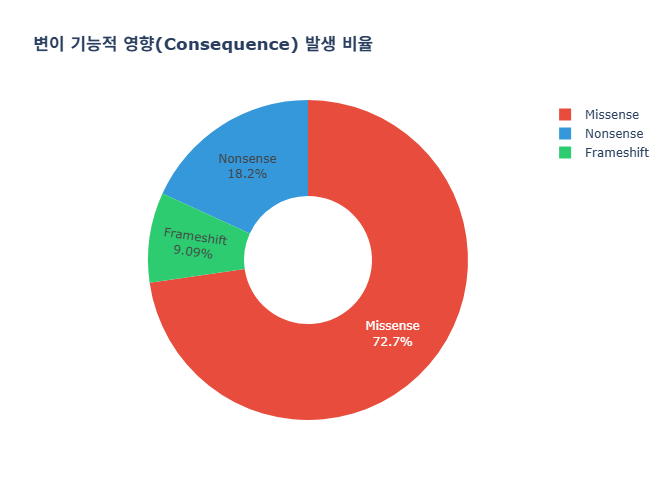

In [22]:
# 변이 결과(consequence) 비율 집계
consequence_counts = (
    mutation_consequence['consequence']
    .value_counts()
    .reset_index()
)

consequence_counts.columns = ['consequence', 'count']

# 도넛 차트 생성
fig_pie = go.Figure(data=[go.Pie(
    labels=consequence_counts['consequence'],
    values=consequence_counts['count'],
    hole=0.4,
    textinfo='label+percent',
    marker=dict(colors=['#e74c3c', '#3498db', '#2ecc71', '#f1c40f'])
)])

fig_pie.update_layout(
    title_text='<b>변이 기능적 영향(Consequence) 발생 비율</b>',
    template="plotly_white",
    height=500
)

fig_pie.show()


#### <연령대별 주요 유전자 변이 발생 양상 비교>

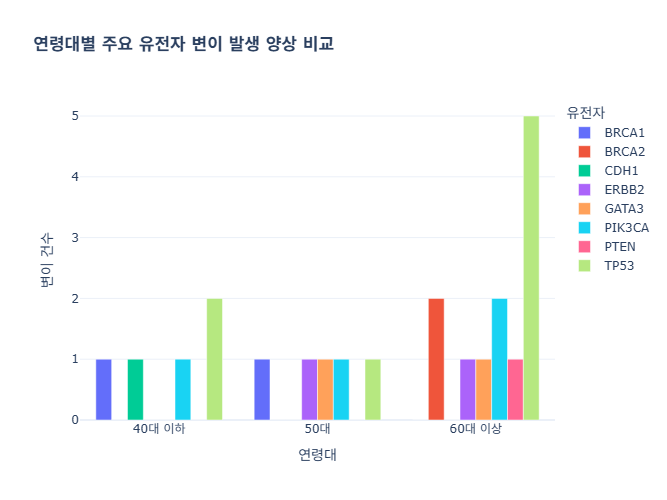

In [23]:
import pandas as pd
import plotly.express as px

# 1) 연령대 파생변수 생성
bins = [0, 49, 59, 100]
labels = ['40대 이하', '50대', '60대 이상']
df_merged['age_group'] = pd.cut(df_merged['age'], bins=bins, labels=labels)

# 2) 연령대 & 유전자별 변이 건수 집계 (NaN 제외)
age_gene = (
    df_merged.dropna(subset=['gene'])
    .groupby(['age_group', 'gene'], observed=False)
    .size()
    .reset_index(name='count')
)

# 3) 연령대별 유전자 변이 그룹 바 차트 시각화
fig_age = px.bar(
    age_gene,
    x='age_group',
    y='count',
    color='gene',
    barmode='group', # 막대를 연령대별로 나란히 배치
    title='<b>연령대별 주요 유전자 변이 발생 양상 비교</b>',
    labels={'age_group': '연령대', 'count': '변이 건수', 'gene': '유전자'},
    template='plotly_white',
    height=500
)

fig_age.show()

#### <병기별 평균 변이수>

In [24]:
patient_mutation_count = (
    df_merged.groupby('patient_id')['gene']
    .count()#행의 수를 count->mutation 횟수 의미
    .reset_index(name='mutation_count')
)
patient_mutation_count

,patient_id,mutation_count
0,P001,3
1,P002,2
2,P003,1
3,P004,3
4,P005,4
5,P006,1
6,P007,2
7,P008,2
8,P009,1
9,P010,3


In [25]:
patient_stage = clinical[['patient_id', 'stage']]
patient_stage

,patient_id,stage
0,P001,II
1,P002,III
2,P003,I
3,P004,II
4,P005,NaN
5,P006,II
6,P007,I
7,P008,III
8,P009,II
9,P010,IV


In [26]:

stage_mutation = pd.merge(
    patient_stage,
    patient_mutation_count,
    on='patient_id',
    how='left'
)
stage_mutation

,patient_id,stage,mutation_count
0,P001,II,3
1,P002,III,2
2,P003,I,1
3,P004,II,3
4,P005,NaN,4
5,P006,II,1
6,P007,I,2
7,P008,III,2
8,P009,II,1
9,P010,IV,3


In [27]:
stage_summary = (
    stage_mutation
    .groupby('stage')['mutation_count']
    .agg(['count', 'mean', 'median', 'sum'])
    .reset_index()
)
stage_summary

,stage,count,mean,median,sum
0,I,2,1.500000,1.5,3
1,II,5,1.600000,1.0,8
2,III,3,1.333333,2.0,4
3,IV,1,3.000000,3.0,3


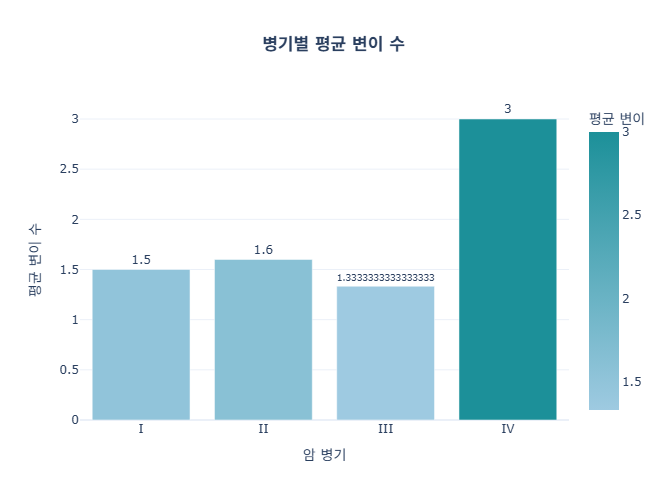

In [28]:
import plotly.express as px
mutation_mean = stage_summary

custom_blues = [
    [0.0, '#9ecae1'], 
    [1.0, '#1c9099'] 
]

fig_bar_2 = px.bar(
    mutation_mean,
    x = 'stage',
    y = 'mean',
    text = 'mean',
    title = '<b>병기별 평균 변이 수</b>',
    labels = {'stage': '병기(stage)', 'mean': '평균 변이 '},
    color = 'mean',
    color_continuous_scale = custom_blues
)

fig_bar_2.update_traces(textposition = 'outside')
fig_bar_2.update_layout(
    title_x = 0.5,  
    xaxis_title = "암 병기",
    yaxis_title = "평균 변이 수",
    template = "plotly_white",
    height = 500
)

fig_bar_2.show()

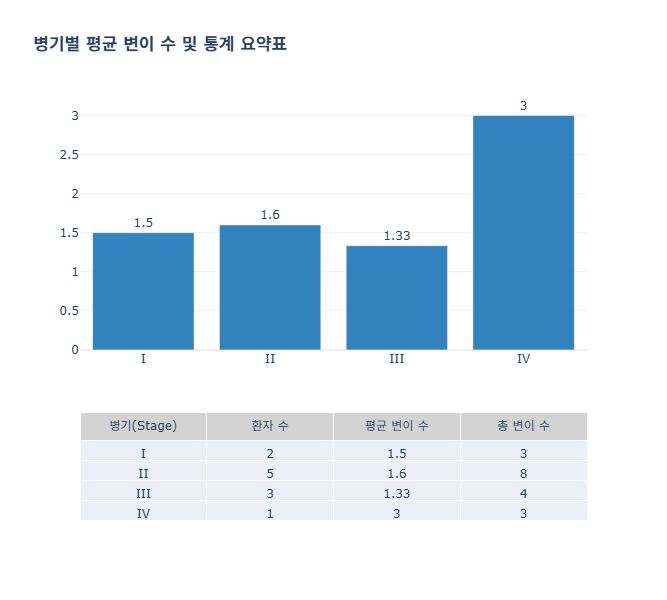

In [29]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1행 2열 또는 2행 1열 구조로 차트 + 표 배치
fig = make_subplots(
    rows=2, cols=1,
    row_heights=[0.7, 0.3],
    specs=[[{"type": "bar"}], [{"type": "table"}]]
)

# 위쪽: 바 차트
fig.add_trace(
    go.Bar(
        x=stage_summary['stage'],
        y=stage_summary['mean'],
        text=stage_summary['mean'].round(2),
        textposition='outside',
        marker_color='#3182bd'
    ),
    row=1, col=1
)

# 아래쪽: 요약 표
fig.add_trace(
    go.Table(
        header=dict(values=['병기(Stage)', '환자 수', '평균 변이 수', '총 변이 수'], fill_color='lightgrey'),
        cells=dict(values=[stage_summary['stage'], stage_summary['count'], stage_summary['mean'].round(2), stage_summary['sum']])
    ),
    row=2, col=1
)

fig.update_layout(title_text="<b>병기별 평균 변이 수 및 통계 요약표</b>", template="plotly_white", height=600)
fig.show()